---
title: "L4-06 · Potential outcomes and randomization"
short_title: "Potential outcomes and randomization"
subtitle: "Each unit has an outcome for every treatment but shows only one, so causal effects are averages over a table we can never see in full; randomization makes the visible half a fair sample of each invisible column."
description: "Define potential outcomes and the average treatment effect, state the four assumptions that identify it from a treated-versus-control contrast, and show why randomization delivers them."
tags: [level-4, coursebook]
---

(lesson-l4-06)=

:::{div}
:class: qcai-meta
![Level 4 icon](../../_static/icons/qicon-level-4.svg) **Level 4 · Undergraduate** · about 105 minutes  
**Big idea.** Each unit has an outcome for every treatment but shows only one, so causal effects are averages over a table we can never see in full; randomization makes the visible half a fair sample of each invisible column.  
**Before this lesson.** [L4-01](#lesson-l4-01), [L4-04](#lesson-l4-04), [L3-10](#lesson-l3-10)  
**Lab.** [Confounding and intervention](../../labs/03-causal-inference.ipynb)
:::

## What you will be able to do

- Write a potential outcomes table, compute individual effects, the ATE and the ATT, and explain the fundamental problem of causal inference.
- Decompose a naive treated-minus-control contrast into the effect on the treated plus selection bias, and compute both parts.
- State SUTVA, consistency, exchangeability and positivity, prove that together they identify the ATE, and prove that the difference in means is unbiased under complete randomization.
- Enumerate or simulate a randomization distribution and explain why it is centered on the ATE although single experiments miss it.

## Why this matters

A tutoring program is open to anyone who signs up. At the end of term, students who signed up score $6.25$ points higher than those who did not. Is $6.25$ the effect of tutoring? Not necessarily: the students who sign up may be the ones who would have scored higher anyway. In the example of this lesson the true average effect is $4$, and the extra $2.25$ comes from who chose the program.

Lessons [L4-01](#lesson-l4-01) to [L4-05](#lesson-l4-05) described causal effects with graphs and the $do$ operator. This lesson uses the second great language of causal inference, potential outcomes, which writes the same questions as comparisons between outcomes under different treatments [@neyman1990; @rubin1974; @hernan]. It makes one fact impossible to miss: half of the data we would need is always missing. It also explains, line by line, why a randomized experiment is trusted more than any adjustment: randomization makes the key assumption true by design instead of by argument.

:::{dropdown} Key terms

**Potential outcome**
: $Y_i(x)$, the outcome unit $i$ would have if the treatment were set to $x$; with two options each unit has a pair $(Y_i(0), Y_i(1))$.

**Average treatment effect (ATE)**
: $E[Y(1) - Y(0)] = E[Y(1)] - E[Y(0)]$, the mean of the individual effects over the population.

**Fundamental problem of causal inference**
: For each unit at most one potential outcome is observed, so no individual effect $Y_i(1) - Y_i(0)$ is ever seen directly.

**SUTVA**
: Stable unit treatment value assumption: a unit's outcome depends only on its own treatment (no interference), and each treatment value has one version.

**Consistency**
: If unit $i$ actually receives $X_i = x$, its observed outcome is $Y_i = Y_i(x)$.

**Exchangeability**
: $Y(x) \perp\!\!\!\perp X$ for each $x$: the potential outcomes carry no information about which treatment was received.

**Positivity**
: Every treatment value being compared has a positive probability, $0 < P(X = 1) < 1$ (within each stratum, for conditional versions).

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l4_06 as _lessonfigs

## Two outcomes per unit, one observed

:::{prf:definition} Potential outcomes and average effects
:label: def-l4-06-po
For a binary treatment, each unit $i$ in a population has two **potential outcomes**, $Y_i(1)$ under treatment and $Y_i(0)$ under control. Its **individual effect** is $\tau_i = Y_i(1) - Y_i(0)$. The **average treatment effect** is [](#eq-l4-06-ate), and the **average effect on the treated** is $\text{ATT} = E[Y(1) - Y(0) \mid X = 1]$, the average over units that actually receive treatment.
:::

$$
\text{ATE} = E[Y(1) - Y(0)] = E[Y(1)] - E[Y(0)]
$$ (eq-l4-06-ate)

The table below the animation lists eight units, A to H, with both potential outcomes, a view only an oracle could have. The $Y(0)$ column is $0, 1, 1, 2, 2, 3, 3, 4$ (mean 2) and the $Y(1)$ column is $3, 5, 7, 4, 8, 6, 7, 8$ (mean 6). The individual effects $3, 4, 6, 2, 6, 3, 4, 4$ differ from unit to unit, and their mean is the ATE, $6 - 2 = 4$. Effects are heterogeneous; the ATE is one summary of them, not the effect on every unit.

:::{figure} ../../_static/animations/l4_06_po_table.mp4
:alt: A table of eight units with columns Y(0), Y(1) and the individual effect. Then a treatment column appears and one potential outcome per row turns into a question mark, as does every individual effect. The naive contrast 6.25 is split into 4.25 plus 2.00.
:width: 100%

The science table, then reality: each unit reveals only the column of the treatment it chose. The naive contrast $6.25$ is the effect on the treated, $4.25$, plus selection bias, $2.00$.
:::

:::{dropdown} What the animation shows
Eight rows, units A to H, show $Y(0)$ in blue, $Y(1)$ in violet and the effect $Y(1) - Y(0)$. The column means are 2, 6 and 4, and the oracle's ATE is $E[Y(1)] - E[Y(0)] = 6 - 2 = 4$. Then reality takes over: the four units with the highest $Y(0)$, E to H, choose treatment, so a column $X$ appears with values 0, 0, 0, 0, 1, 1, 1, 1. For treated units the $Y(0)$ entry becomes a question mark; for control units the $Y(1)$ entry does; every individual effect becomes a question mark. The naive contrast is the treated mean of $Y(1)$ minus the control mean of $Y(0)$: $7.25 - 1.00 = 6.25$. It splits into $4.25$, the effect on the treated, plus $2.00$, the selection bias $E[Y(0) \mid X=1] - E[Y(0) \mid X=0] = 3 - 1$.
:::

:::{important} The fundamental problem
No unit ever shows both potential outcomes, so no individual effect is ever observed [@hernan]. Every causal estimate compares *different* units (or the same unit at different times, which needs its own assumptions). The question is always which assumptions make the units in one arm stand in for the units in the other.
:::

## Selection bias

:::{prf:proposition} Decomposition of the naive contrast
:label: prop-l4-06-decomp
Under consistency, $E[Y \mid X = 1] - E[Y \mid X = 0] = \text{ATT} + \big(E[Y(0) \mid X = 1] - E[Y(0) \mid X = 0]\big)$. The second term is the **selection bias**: the difference the two groups would show if nobody were treated [@seeing].
:::

:::{prf:proof}
By consistency, $E[Y \mid X = 1] = E[Y(1) \mid X = 1]$ and $E[Y \mid X = 0] = E[Y(0) \mid X = 0]$. Add and subtract $E[Y(0) \mid X = 1]$: $E[Y(1) \mid X = 1] - E[Y(0) \mid X = 1] + E[Y(0) \mid X = 1] - E[Y(0) \mid X = 0]$. The first difference is the ATT; the second is the selection bias.
:::

In the self-selected example the treated units E to H have $Y(1)$ values $8, 6, 7, 8$ (mean $7.25$) and the control units A to D have $Y(0)$ values $0, 1, 1, 2$ (mean $1.00$), so the naive contrast is $6.25$. The treated units' own effects are $6, 3, 4, 4$, so $\text{ATT} = 4.25$. Their $Y(0)$ values average $3$ against $1$ for the controls, a selection bias of $2.00$. Check: $4.25 + 2.00 = 6.25$. The ATT differs from the ATE ($4.25$ versus $4$) because the effects are heterogeneous.

```{mermaid}
graph LR
  subgraph S1[self-selection]
  U1[ability U] --> X1[X chosen]
  U1 --> Y1[Y]
  X1 --> Y1
  end
  subgraph S2[randomized]
  C[coin] --> X2[X assigned]
  U2[ability U] --> Y2[Y]
  X2 --> Y2
  end
```

*The same story as graphs. Under self-selection an unmeasured ability $U$ drives both the choice and the outcome: a backdoor path, which in potential outcomes language is $Y(0)$ depending on $X$. Under randomization the coin is the only cause of $X$, so there is no backdoor path.*

## Four assumptions that identify the ATE

:::{prf:assumption} SUTVA
:label: asm-l4-06-sutva
Each unit's outcome depends only on its own treatment, $Y_i(x_1, \dots, x_n) = Y_i(x_i)$ (no interference), and there is only one version of each treatment value. Vaccines in a household and classroom peer effects are standard violations.
:::

:::{prf:assumption} Consistency
:label: asm-l4-06-consistency
If $X_i = x$ then $Y_i = Y_i(x)$: the observed outcome is the potential outcome of the treatment actually received. In graph language this is what links the observed $Y$ to the intervention $do(X = x)$ ([L4-01](#lesson-l4-01)).
:::

:::{prf:assumption} Exchangeability
:label: asm-l4-06-exch
$Y(x) \perp\!\!\!\perp X$ for $x = 0, 1$: the treated and control groups would have had the same distribution of $Y(1)$, and of $Y(0)$, had they received the same treatment. In the graph language of [L4-04](#lesson-l4-04) this corresponds to the empty set satisfying the backdoor criterion.
:::

:::{prf:assumption} Positivity
:label: asm-l4-06-pos
$0 < P(X = 1) < 1$, so both conditional means $E[Y \mid X = x]$ are defined.
:::

:::{prf:theorem} Identification of the ATE
:label: thm-l4-06-ident
Under SUTVA, consistency, exchangeability and positivity, $E[Y(x)] = E[Y \mid X = x]$ for $x = 0, 1$, and therefore $\text{ATE} = E[Y \mid X = 1] - E[Y \mid X = 0]$ [@hernan].
:::

:::{prf:proof}
SUTVA makes $Y_i(1)$ and $Y_i(0)$ well-defined numbers for each unit. Positivity makes $E[Y \mid X = x]$ defined. Then $E[Y \mid X = 1] = E[Y(1) \mid X = 1]$ by consistency, because among units with $X = 1$ the observed $Y$ is $Y(1)$. Next, $E[Y(1) \mid X = 1] = E[Y(1)]$ by exchangeability, because $Y(1)$ is independent of $X$. The same two steps give $E[Y \mid X = 0] = E[Y(0)]$. Subtract and use [](#eq-l4-06-ate).
:::

:::{figure} ../../_static/animations/l4_06_assumptions.mp4
:alt: Four cards labeled SUTVA, consistency, exchangeability and positivity with their formulas. Below, the chain E[Y | X = 1] = E[Y(1) | X = 1] = E[Y(1)] grows term by term while the card used at each step flashes.
:width: 100%

Each step of the identification proof uses one card: SUTVA defines the potential outcomes, consistency swaps $Y$ for $Y(1)$, exchangeability removes the conditioning, positivity keeps both sides defined.
:::

:::{dropdown} What the animation shows
Four cards appear: SUTVA with $Y_i(x_1, \dots, x_n) = Y_i(x_i)$, consistency with $X_i = x \Rightarrow Y_i = Y_i(x)$, exchangeability with $Y(x) \perp\!\!\!\perp X$, and positivity with $0 < P(X = 1) < 1$. The SUTVA card flashes: it makes $Y(1)$ and $Y(0)$ well defined. The expression $E[Y \mid X = 1]$ appears and grows into $E[Y \mid X = 1] = E[Y(1) \mid X = 1]$ while the consistency card flashes, then into $= E[Y(1)]$ while the exchangeability card flashes. The positivity card flashes to show that both sides are defined. The final line reads $E[Y \mid X=1] - E[Y \mid X=0] = E[Y(1)] - E[Y(0)] = \text{ATE}$.
:::

:::{prf:corollary} Conditional exchangeability gives standardization
:label: cor-l4-06-cond
If instead $Y(x) \perp\!\!\!\perp X \mid Z$ (conditional exchangeability) and $0 < P(X = 1 \mid Z = z) < 1$ for every $z$, then $E[Y(x)] = \sum_z E[Y \mid X = x, Z = z]\, P(z)$, the standardization formula of [L4-04](#lesson-l4-04).
:::

:::{prf:proof}
$E[Y(x)] = \sum_z E[Y(x) \mid Z = z] P(z) = \sum_z E[Y(x) \mid X = x, Z = z] P(z) = \sum_z E[Y \mid X = x, Z = z] P(z)$, using the law of total expectation, then conditional exchangeability within each stratum, then consistency. Positivity makes every term defined. Graphically, a set $Z$ that satisfies the backdoor criterion delivers conditional exchangeability, so the two languages give the same formula [@pearlcausality].
:::

## Randomization

In **complete randomization** exactly $n_1$ of the $N$ units are treated and every one of the $\binom{N}{n_1}$ subsets is equally likely. With $N = 8$ and $n_1 = 4$ there are $\binom{8}{4} = 70$ assignments. Because the assignment is generated by a device that never looks at the units, it is independent of their potential outcomes: exchangeability holds by design [@openstax_design].

:::{prf:proposition} The difference in means is unbiased
:label: prop-l4-06-unbiased
Under SUTVA, consistency and complete randomization with $0 < n_1 < N$, the difference in means $\hat\tau = \frac{1}{n_1}\sum_{i: X_i = 1} Y_i - \frac{1}{n_0}\sum_{i: X_i = 0} Y_i$, with $n_0 = N - n_1$, satisfies $E[\hat\tau] = \frac1N \sum_i \big(Y_i(1) - Y_i(0)\big)$, the ATE of the $N$ units. The expectation is over the random assignment; the potential outcomes are fixed [@imbensrubin2015].
:::

:::{prf:proof}
By consistency, $\hat\tau = \frac{1}{n_1}\sum_i X_i Y_i(1) - \frac{1}{n_0}\sum_i (1 - X_i) Y_i(0)$, where only the indicators $X_i$ are random. Each unit is in the treated subset of exactly $\binom{N-1}{n_1-1}$ of the $\binom{N}{n_1}$ equally likely subsets, so $E[X_i] = n_1/N$ and $E[1 - X_i] = n_0/N$. By linearity, $E[\hat\tau] = \frac{1}{n_1}\sum_i \frac{n_1}{N} Y_i(1) - \frac{1}{n_0}\sum_i \frac{n_0}{N} Y_i(0) = \frac1N\sum_i Y_i(1) - \frac1N\sum_i Y_i(0)$.
:::

:::{figure} ../../_static/animations/l4_06_randomization.mp4
:alt: Eight unit circles at the top; at each draw four turn violet (treated) and four blue. Each draw drops one dot into a dot plot of the difference in means and one into a dot plot of baseline imbalance. After ten draws, the dots of all 70 assignments fill in, centered on 4 and on 0.
:width: 100%

One random assignment at a time: estimates scatter around the ATE and baseline imbalance scatters around 0. Over all $70$ assignments the estimates average exactly 4, with variance $29/28$.
:::

:::{dropdown} What the animation shows
Eight circles, A to H, show each unit's $Y(0)$. A draw of complete randomization colors four circles violet for treatment and four blue for control. For each draw the screen shows the difference in means $\hat\tau$ and the baseline imbalance, the treated mean of $Y(0)$ minus the control mean of $Y(0)$, and drops a dot into one dot plot for each. Ten draws are shown one by one; single estimates land as far from 4 as 2 or 6, and imbalances land away from 0. Then the dots of all 70 possible assignments fill in. The estimates average exactly 4, the ATE, with variance $29/28$, and the imbalances average exactly 0.
:::


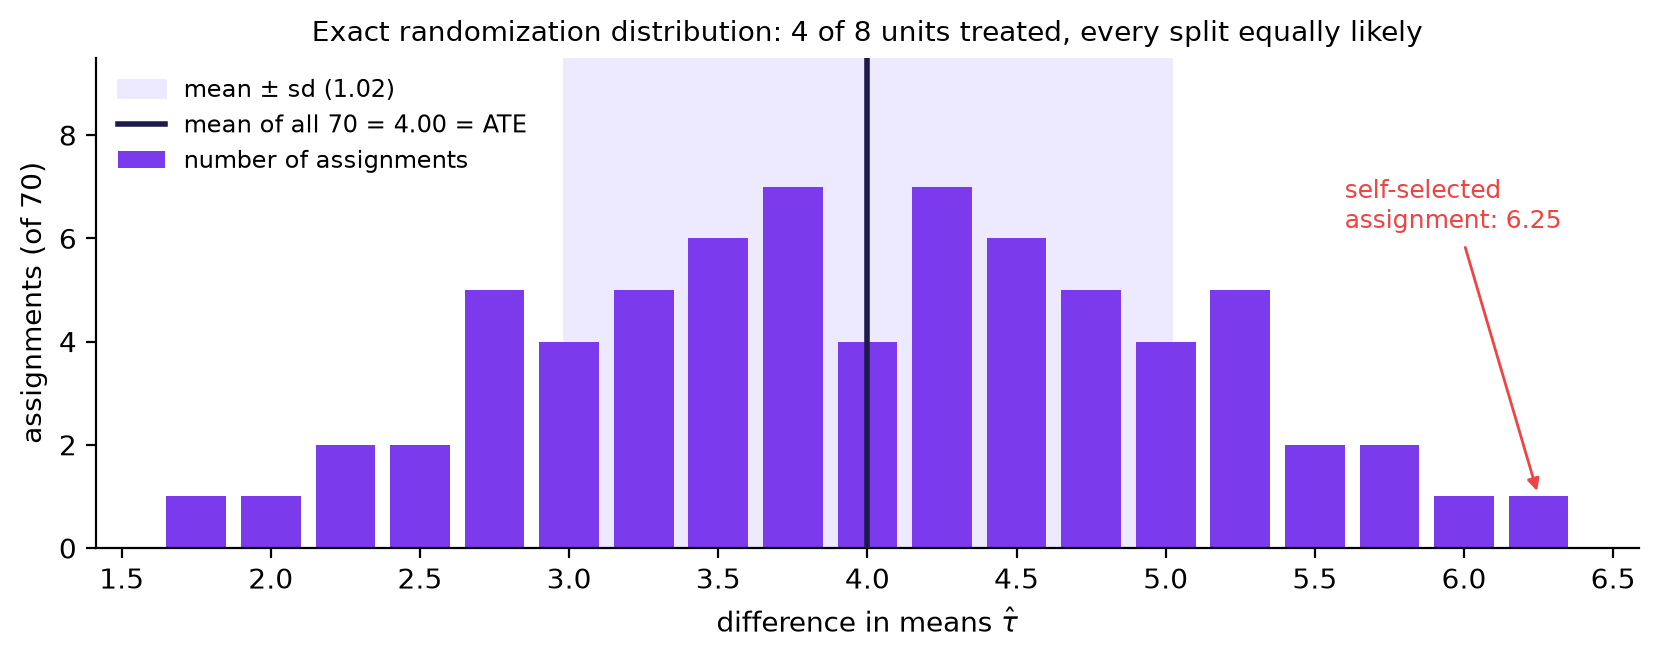

In [2]:
_show_mpl(_lessonfigs.exact_distribution())

*The exact randomization distribution of $\hat\tau$ for the eight-unit table: one bar per possible value, height the number of the 70 assignments that give it. The mean is the ATE, 4. The self-selected assignment E to H is one of the 70 and gives the extreme value $6.25$; the problem with self-selection is not that assignment but that it was chosen because of $Y(0)$.*

:::{prf:remark} How spread out is one experiment?
The variance of $\hat\tau$ over the 70 assignments is $29/28 \approx 1.04$. A classical formula due to Neyman [@neyman1990; @imbensrubin2015] gives it exactly as $S_1^2/n_1 + S_0^2/n_0 - S_\tau^2/N$, where $S_1^2$, $S_0^2$ and $S_\tau^2$ are the variances (divisor $N - 1$) of the $Y(1)$ column, the $Y(0)$ column and the individual effects: $\tfrac{24/7}{4} + \tfrac{12/7}{4} - \tfrac{2}{8} = \tfrac{29}{28}$. The last term needs both columns and can never be estimated, so the usual standard error, which drops it, is conservative. The code below checks the formula by enumeration.
:::


In [3]:
_show(_lessonfigs.randomization_explorer())

**Explore.** Change the number of units $N$ (the eight-unit table copied $N/8$ times, half treated). Both histograms narrow around their centers as $N$ grows; the self-selected value $6.25$ never moves.

:::{dropdown} What the figure shows
The first panel is a histogram of the difference in means over 2000 simulated complete randomizations, with a solid line at the true ATE 4 and a dashed line at the self-selected contrast 6.25. The second panel is a histogram of the baseline imbalance in $Y(0)$. At $N = 8$ the estimates spread from about 2 to 6 (standard deviation about 1.0) and the imbalance from $-2$ to $2$. At $N = 256$ the estimates concentrate near 4 (standard deviation under 0.2) and the imbalance near 0. Self-selection stays biased at every $N$.
:::

:::{warning} What randomization does not do
It does not balance every realized sample: one experiment can be unlucky, as the dot plots show. It does not make participants follow their assignment: with nonadherence, the comparison of randomized groups estimates the effect of *assignment* (intention to treat), not of treatment received. It does not repair missing outcomes or interference between units. Each of these changes the target or the analysis.
:::

## Compute it

Exact arithmetic with `fractions`: the ATE of the table, the decomposition of the self-selected contrast, the 70-assignment randomization distribution with Neyman's variance formula, and a Bernoulli design (an independent coin per unit, from the course engine's seeded generator `qcai.science.rng`) in which an arm can come out empty and must be skipped.


In [4]:
import itertools
from fractions import Fraction as F
from qcai import science

Y0 = [0, 1, 1, 2, 2, 3, 3, 4]          # the science table of the lesson (units A to H)
Y1 = [3, 5, 7, 4, 8, 6, 7, 8]
N = len(Y0)
tau = [b - a for a, b in zip(Y0, Y1)]
print("ATE =", F(sum(tau), N))

def diff_in_means(T):
    """Treated mean of Y(1) minus control mean of Y(0): what we see when T is treated (consistency)."""
    C = [i for i in range(N) if i not in T]
    return F(sum(Y1[i] for i in T), len(T)) - F(sum(Y0[i] for i in C), len(C))

# self-selection: the four units with the largest Y(0) take the treatment
T_self = (4, 5, 6, 7)
att = F(sum(tau[i] for i in T_self), 4)
bias = F(sum(Y0[i] for i in T_self), 4) - F(sum(Y0[i] for i in range(4)), 4)
print("self-selected contrast", diff_in_means(T_self), "= ATT", att, "+ selection bias", bias)

# complete randomization: all C(8, 4) = 70 assignments equally likely
est = [diff_in_means(T) for T in itertools.combinations(range(N), 4)]
mean = sum(est) / len(est)
var = sum((e - mean) ** 2 for e in est) / len(est)
def S2(v):                                 # finite-population variance with divisor N - 1
    mu = F(sum(v), len(v))
    return sum((x - mu) ** 2 for x in v) / (len(v) - 1)
neyman = S2(Y1) / 4 + S2(Y0) / 4 - S2(tau) / N
print(len(est), "assignments: mean", mean, " variance", var, " Neyman's formula", neyman)
print("range of estimates:", float(min(est)), "to", float(max(est)))

# Bernoulli design: one fair coin per unit (the course engine's seeded generator); an arm can be empty
coin = science.rng(2024)
total, kept, empty = F(0), 0, 0
for _ in range(20000):
    T = tuple(i for i in range(N) if coin() < 0.5)
    if len(T) in (0, N):
        empty += 1
        continue
    total += diff_in_means(T)
    kept += 1
print(f"coin flips: mean estimate {float(total / kept):.3f} over {kept} experiments; {empty} had an empty arm")

ATE = 4
self-selected contrast 25/4 = ATT 17/4 + selection bias 2
70 assignments: mean 4  variance 29/28  Neyman's formula 29/28
range of estimates: 1.75 to 6.25
coin flips: mean estimate 3.993 over 19842 experiments; 158 had an empty arm


:::{prf:remark} Two designs
Complete randomization fixes the arm sizes, so both arms are never empty. Independent coin flips (a Bernoulli design) can leave an arm empty, with probability $2/2^N = 1/128$ for $N = 8$; then $\hat\tau$ is undefined. Given the number of treated units, a Bernoulli design is a complete randomization, so the estimator is still unbiased once empty-arm draws are excluded, as the simulation shows.
:::

## Worked example

:::{admonition} Every possible experiment on four units
:class: tip

Four units have $(Y(0), Y(1))$ equal to $a = (1, 3)$, $b = (2, 2)$, $c = (4, 7)$ and $d = (3, 2)$. Compute the ATE. Then list all complete randomizations with two treated units, the difference in means for each, and their average.

1. Individual effects are $2, 0, 3, -1$; their mean is the ATE, $4/4 = 1$.
2. There are $\binom{4}{2} = 6$ assignments. Treated $\{a, b\}$: $(3 + 2)/2 - (4 + 3)/2 = -1$. Treated $\{a, c\}$: $5 - 2.5 = 2.5$. Treated $\{a, d\}$: $2.5 - 3 = -0.5$.
3. Treated $\{b, c\}$: $4.5 - 2 = 2.5$. Treated $\{b, d\}$: $2 - 2.5 = -0.5$. Treated $\{c, d\}$: $4.5 - 1.5 = 3$.
4. Average of the six estimates: $(-1 + 2.5 - 0.5 + 2.5 - 0.5 + 3)/6 = 6/6 = 1$.

**Result.** The ATE is 1. Single experiments give anything from $-1$ to $3$, even the wrong sign, but the average over the assignment distribution is exactly the ATE, as [](#prop-l4-06-unbiased) promises.
:::

## Exercises

**1. (Core)** Four model units have potential outcome pairs $(Y(0), Y(1))$ of $(1, 3)$, $(2, 2)$, $(4, 7)$ and $(3, 2)$. Calculate each individual effect and the population ATE. Is the treatment good for every unit?

:::{dropdown} Solution
The individual effects are $2, 0, 3, -1$. Their sum is 4 over four units, so the ATE is 1 outcome unit. No: one unit is unaffected and one is harmed ($-1$), although the average effect is positive.
:::

**2. (Core)** In the eight-unit table, suppose units C, E, G and H choose treatment. Compute the naive contrast, the ATT and the selection bias, and check the decomposition.

:::{dropdown} Solution
Treated $Y(1)$: $7, 8, 7, 8$, mean $7.5$. Control (A, B, D, F) $Y(0)$: $0, 1, 2, 3$, mean $1.5$. Naive contrast $6.0$. ATT: effects of C, E, G, H are $6, 6, 4, 4$, mean $5.0$. Selection bias: treated $Y(0)$ are $1, 2, 3, 4$, mean $2.5$, minus $1.5$, giving $1.0$. Check: $5.0 + 1.0 = 6.0$.
:::

**3. (Stretch)** Show that under exchangeability the ATT equals the ATE. Then explain in one sentence why they differ in the self-selected example.

:::{dropdown} Solution
$\text{ATT} = E[Y(1) \mid X = 1] - E[Y(0) \mid X = 1] = E[Y(1)] - E[Y(0)] = \text{ATE}$, using $Y(x) \perp\!\!\!\perp X$ for each $x$. In the self-selected example $Y(0)$ and $Y(1)$ depend on $X$ (the treated have high $Y(0)$), so exchangeability fails and the treated units' average effect, $4.25$, differs from the population's, $4$.
:::

**4. (Stretch)** In a Bernoulli design each of $N$ units is treated by an independent fair coin. Find the probability that an arm is empty, evaluate it for $N = 8$ and $N = 20$, and explain why the difference in means is still unbiased if such draws are discarded.

:::{dropdown} Solution
An arm is empty when all coins agree: $P = 2 \cdot (1/2)^N = 2^{1-N}$. For $N = 8$ this is $1/128 \approx 0.0078$; for $N = 20$ it is $2^{-19} \approx 1.9 \times 10^{-6}$. Conditional on the number of treated units $n_1$, every subset of size $n_1$ is equally likely, which is complete randomization, so by [](#prop-l4-06-unbiased) the conditional mean of $\hat\tau$ is the ATE for each $n_1$ from 1 to $N - 1$. Averaging over $n_1$ (with empty arms excluded) still gives the ATE.
:::

**5. (Challenge)** Two roommates can each be vaccinated. Unit 1's probability of illness depends on both treatments: $0.4$ if neither is vaccinated, $0.1$ if only unit 1 is, $0.3$ if only the roommate is, $0.05$ if both are. Which assumption fails? Compute unit 1's effect of its own vaccination for each roommate status, and the effect a trial would estimate if each person were vaccinated by an independent fair coin.

:::{dropdown} Solution
SUTVA (no interference) fails: unit 1's outcome depends on the roommate's treatment, so '$Y_1(1)$' is not one number. The effect of own vaccination on the risk is $0.1 - 0.4 = -0.3$ when the roommate is unvaccinated and $0.05 - 0.3 = -0.25$ when the roommate is vaccinated. With independent fair coins the roommate is vaccinated half the time, so the trial estimates the average $0.5(-0.3) + 0.5(-0.25) = -0.275$, an effect that depends on the vaccination policy for others, not a property of unit 1 alone.
:::

**6. (Challenge)** A trial randomizes within two strata of $Z$, each half of the population, treating 80% of units with $Z = 1$ and 20% with $Z = 0$. Mean potential outcomes are $E[Y(0) \mid Z = 0] = 1$, $E[Y(1) \mid Z = 0] = 3$, $E[Y(0) \mid Z = 1] = 4$, $E[Y(1) \mid Z = 1] = 7$. Compute the ATE, the naive contrast, and the standardized contrast. Which version of exchangeability holds?

:::{dropdown} Solution
ATE $= 0.5(3 - 1) + 0.5(7 - 4) = 2.5$. By Bayes' rule $P(Z = 1 \mid X = 1) = 0.8$ and $P(Z = 1 \mid X = 0) = 0.2$, so $E[Y \mid X = 1] = 0.2(3) + 0.8(7) = 6.2$ and $E[Y \mid X = 0] = 0.8(1) + 0.2(4) = 1.6$: a naive contrast of $4.6$. Standardizing with $P(Z) = (0.5, 0.5)$: $0.5(3) + 0.5(7) - [0.5(1) + 0.5(4)] = 5 - 2.5 = 2.5$, the ATE. Randomization within strata gives conditional exchangeability $Y(x) \perp\!\!\!\perp X \mid Z$, not marginal exchangeability, so [](#cor-l4-06-cond) applies.
:::

## Check your understanding

**1. What does random assignment establish in its assignment distribution?**

- **A.** Every finite sample is perfectly balanced
- **B.** Every participant receives the assigned treatment
- **C.** Every unit has the same treatment effect
- **D.** Treatment is independent of the potential outcomes

:::{dropdown} Show the answer
**D. Treatment is independent of the potential outcomes**

Random assignment provides exchangeability by design. Perfect realized balance, full adherence and homogeneous effects are different properties and do not follow.
:::

**2. In the eight-unit example, the naive contrast is $6.25$ and the effect on the treated is $4.25$. What is the selection bias?**

- **A.** 2.25
- **B.** 0.25
- **C.** 2.00
- **D.** 6.25

:::{dropdown} Show the answer
**C. 2.00**

Naive contrast = ATT + selection bias, so the bias is $6.25 - 4.25 = 2.00$, the difference in average $Y(0)$ between the groups, $3 - 1$. The remaining $0.25$ between the ATT and the ATE comes from heterogeneous effects.
:::

**3. Which step of the identification proof uses consistency?**

- **A.** $E[Y(1)] - E[Y(0)] = E[Y(1) - Y(0)]$
- **B.** $E[Y \mid X = 1] = E[Y(1) \mid X = 1]$
- **C.** $E[Y(1) \mid X = 1] = E[Y(1)]$
- **D.** $0 < P(X = 1) < 1$

:::{dropdown} Show the answer
**B. $E[Y \mid X = 1] = E[Y(1) \mid X = 1]$**

Consistency replaces the observed $Y$ by $Y(1)$ among units that received $X = 1$. Removing the conditioning uses exchangeability; the third step is linearity of expectation; the last is positivity.
:::

**4. A sample mean has standard error $s$ with $n$ independent observations. What is its standard error with $4n$ observations?** *(Review of [L3-10](#lesson-l3-10))*

- **A.** $s$
- **B.** $2s$
- **C.** $s/4$
- **D.** $s/2$

:::{dropdown} Show the answer
**D. $s/2$**

The standard error scales as $1/\sqrt{n}$, so four times as many observations halve it. The randomization explorer shows the same narrowing of the distribution of $\hat\tau$.
:::

## Common misconceptions

- **"Randomization guarantees that the two groups are balanced."** It guarantees balance on average over the assignment distribution. A single experiment can be unbalanced, as the dot plots show; the uncertainty calculation accounts for that.
- **"The ATE is the effect on each unit."** It is the mean of individual effects that can differ in size and sign. In the four-unit example the ATE is 1 while one unit is harmed.
- **"Potential outcomes and causal graphs are rival theories."** They describe the same causal quantities. Consistency links $Y$ to $Y(x)$ as the do operator links $Y$ to an intervention, and a valid backdoor set gives conditional exchangeability [@pearlcausality].
- **"A randomized trial always measures the effect of taking the treatment."** It measures the effect of assignment. If some participants do not follow their assignment, the effect of treatment actually received needs further assumptions.

:::{caution} Scope and limits
This lesson uses a finite population with fixed potential outcomes and the expectation over random assignment; the superpopulation view, where units are also sampled, leads to the same identification argument with different variance formulas. Identification by randomization relies on SUTVA, consistency, adherence to the assigned treatment and complete outcome data; none of these is guaranteed by the coin. All tables and numbers are made up for teaching, and the simulations check the algebra, not any real program.
:::

:::{seealso} Where this leads
[L4-07](#lesson-l4-07) asks in general when a causal quantity is determined by the observed distribution. [L4-09](#lesson-l4-09) studies counterfactuals for individual units, which need a structural causal model rather than only the averages used here. [L4-10](#lesson-l4-10) asks when an effect measured in one population carries over to another.
:::

:::{dropdown} For instructors

**Why this lesson.** Students who first meet causal inference through graphs often treat 'correlation is not causation' as a slogan. The potential outcomes table makes the missing-data structure concrete, and the selection-bias decomposition says exactly what goes wrong [@hernan; @seeing].

**Teaching notes.**

- Hand out the eight-unit table with both columns, let groups compute the ATE, then cover one column per row according to self-selection and ask them to estimate it again.
- Run the 70-assignment enumeration as a class activity: each group draws a few assignments by hand, the class pools the estimates, and the pooled mean approaches 4.
- Map each assumption to its graph counterpart: exchangeability to an empty backdoor set, conditional exchangeability to a valid adjustment set, consistency to the do operator [@pearlcausality].
- Separate the two sources of randomness explicitly: random assignment (used here) and random sampling of units ([L3-10](#lesson-l3-10)).

**Assessment.** The second core exercise and the second check question test the decomposition; the third check question and the stretch exercise test the identification argument; the challenge exercises test whether students can spot violated assumptions (interference) and use conditional exchangeability [@bradyneal].

**Going further.** Introduce Fisher's randomization test: under the sharp null $Y_i(1) = Y_i(0)$ for every unit, all 70 assignments are known, so the observed $\hat\tau$ can be ranked among them to give an exact p-value. Then compare it with the large-sample interval for the ATE. Hernán and Robins develop the potential outcomes view with many examples [@hernan].

:::

## References

This lesson draws on [@hernan; @seeing; @bradyneal; @pearlcausality; @openstax_design; @pearl; @rubin1974; @neyman1990; @imbensrubin2015].

**Further reading.**

- [@hernan]: Chapters 1 to 3 define potential outcomes, exchangeability, positivity and consistency, and treat randomized experiments.
- [@seeing]: The potential outcomes chapter derives the decomposition of the simple difference in outcomes into effect and selection bias.
- [@bradyneal]: Chapter 2 introduces potential outcomes and the identification assumptions with small tables.

**Next:** [L4-07 · Identification before estimation](#lesson-l4-07)
